In [31]:
import os
import urllib.request
import numpy as np
import pandas as pd
import aif360
from aif360.datasets import AdultDataset, GermanDataset, CompasDataset
from aif360.metrics import BinaryLabelDatasetMetric
from sklearn.model_selection import train_test_split
from aif360.algorithms.preprocessing import Reweighing
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import matplotlib.pyplot as plt

# Hide AIF360's warnings 
import logging
logging.getLogger().setLevel(logging.ERROR)

## 1. Selecting and loading datasets

In [32]:
# download the raw data files for Adult, German and COMPAS into AIF360's own data folder,
# so that AdultDataset(), GermanDataset() and CompasDataset() can load them.

base = os.path.join(os.path.dirname(aif360.__file__), "data", "raw")

# base URL of the UCI Machine Learning Repository, where Adult and German are hosted
uci = "https://archive.ics.uci.edu/ml/machine-learning-databases"

# For each dataset: the AIF360 subfolder name -> the files AIF360 expects in it
files = {
    "adult": [f"{uci}/adult/adult.data", f"{uci}/adult/adult.test", f"{uci}/adult/adult.names"],
    "german": [f"{uci}/statlog/german/german.data", f"{uci}/statlog/german/german.doc"],
    "compas": ["https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"],
}

# download each file to the right subfolder, skipping files that are already there
for folder, urls in files.items():
    for url in urls:
        path = os.path.join(base, folder, url.split("/")[-1])  
        if not os.path.exists(path):
            urllib.request.urlretrieve(url, path)
            print("downloaded", path)

In [33]:
# load the three datasets with AIF360 and choose one sensitive attribute per dataset.
# print an overview table of size, group balance and label balance.

# each dataset gets a small "config": the loaded AIF360 dataset + the sensitive attribute we study
datasets = {
    "Adult":  {"data": AdultDataset(),  "attr": "sex"},   # privileged: male
    "German": {"data": GermanDataset(), "attr": "age"},   # privileged: older than 25
    "COMPAS": {"data": CompasDataset(), "attr": "race"},  # privileged: Caucasian
}

# AIF360 encodes the privileged group as 1 and the unprivileged group as 0.
# Metrics and Reweighing need the groups in this format: a list of {attribute: value} dicts.
for cfg in datasets.values():
    cfg["priv"] = [{cfg["attr"]: 1}]
    cfg["unpriv"] = [{cfg["attr"]: 0}]

## 2. Fairness of the original labels (before mitigation)

In [34]:
# measure the bias that is already in the data, using the original labels
# (before any classifier is trained and before Reweighing is applied)

results_before = []
for name, cfg in datasets.items():
    # metric object for this dataset: compares the unprivileged group to the privileged group
    metric = BinaryLabelDatasetMetric(
        cfg["data"],
        unprivileged_groups=cfg["unpriv"],
        privileged_groups=cfg["priv"],
    )
    results_before.append({
        "dataset": name,
        "P(fav | priv)": metric.base_rate(privileged=True),     
        "P(fav | unpriv)": metric.base_rate(privileged=False),  
        "DP_Diff": metric.statistical_parity_difference(),      
        "DIR": metric.disparate_impact(),                       
        "consistency": metric.consistency(n_neighbors=5)[0],   
    })

# collect everything in one table 
original_metrics = pd.DataFrame(results_before).set_index("dataset").round(3)
original_metrics

,P(fav | priv),P(fav | unpriv),DP_Diff,DIR,consistency
dataset,,,,,
Adult,0.312,0.114,-0.199,0.363,0.849
German,0.728,0.579,-0.149,0.795,0.681
COMPAS,0.609,0.511,-0.097,0.840,0.676


## 3. Stratified train/test split

In [35]:
# split each dataset into 70% training and 30% test data.
# We stratify on (sensitive group x label), so both parts keep the same mix of
# privileged/unprivileged people and favorable/unfavorable labels as the full dataset.

SEED = 42  

for name, cfg in datasets.items():
    ds = cfg["data"]
    y = ds.labels.ravel()  # label per row (1 = favorable, 0 = unfavorable)
    s = ds.protected_attributes[:, ds.protected_attribute_names.index(cfg["attr"])]  # group per row (1 = privileged, 0 = unprivileged)

    # Combine group and label into one stratum code: 0, 1, 2 or 3 (the four cells Reweighing uses)
    strata = (2 * s + y).astype(int)

    # Split the row numbers, then use them to take the two subsets from the AIF360 dataset
    train_idx, test_idx = train_test_split(
        np.arange(len(y)), test_size=0.3, stratify=strata, random_state=SEED
    )
    cfg["train"] = ds.subset(train_idx)
    cfg["test"] = ds.subset(test_idx)

## 4. Mitigation: Reweighing on the training data + training the classifiers
Reweighing (pre-processing) assigns each training row a weight W = P(group)·P(label) / P(group, label).
We train a baseline logistic regression as a control group(no weights) and the same model with the Reweighing weights.

In [36]:
# apply Reweighing to the training data, then train two identical classifiers:
# a baseline (original data) and a mitigated model (reweighted data).

def make_model():
    # scale features to mean 0 / std 1, then logistic regression (same setup for both models)
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

for name, cfg in datasets.items():
    train = cfg["train"]

    # reweighing: learn the 4 weights from the training data and attach them to every training row
    rw = Reweighing(unprivileged_groups=cfg["unpriv"], privileged_groups=cfg["priv"])
    cfg["rw"] = rw
    cfg["train_rw"] = rw.fit_transform(train)  

    X_train = train.features
    y_train = train.labels.ravel()

    # baseline: logistic regression on the original training data (every row weight 1)
    cfg["baseline"] = make_model().fit(X_train, y_train)

    # mitigated: identical model, but each row counts according to its Reweighing weight
    cfg["mitigated"] = make_model().fit(
        X_train, y_train,
        logisticregression__sample_weight=cfg["train_rw"].instance_weights,
    )

In [37]:
# show the 4 weights per dataset to check that the reweighted training data has DP_Diff = 0

weights = []
for name, cfg in datasets.items():
    rw = cfg["rw"]
    dp_before = BinaryLabelDatasetMetric(cfg["train"], unprivileged_groups=cfg["unpriv"], privileged_groups=cfg["priv"]).statistical_parity_difference()
    dp_after = BinaryLabelDatasetMetric(cfg["train_rw"], unprivileged_groups=cfg["unpriv"], privileged_groups=cfg["priv"]).statistical_parity_difference()
    weights.append({
        "dataset": name,
        "W(unpriv, fav)": rw.w_up_fav,      # expected > 1: under-represented
        "W(unpriv, unfav)": rw.w_up_unfav,  # expected < 1
        "W(priv, fav)": rw.w_p_fav,         # expected < 1: over-represented
        "W(priv, unfav)": rw.w_p_unfav,     # expected > 1
        "train DP_Diff (original)": dp_before,
        "train DP_Diff (reweighted)": dp_after,  # should be ~0
    })

pd.DataFrame(weights).set_index("dataset").round(3)

,"W(unpriv, fav)","W(unpriv, unfav)","W(priv, fav)","W(priv, unfav)",train DP_Diff (original),train DP_Diff (reweighted)
dataset,,,,,,
Adult,2.183,0.849,0.793,1.094,-0.199,-0.0
German,1.209,0.712,0.961,1.105,-0.149,-0.0
COMPAS,1.065,0.932,0.895,1.164,-0.097,0.0


## 5. Evaluation on the held-out test data
Fairness measures are computed on the models' predictions for the test set;
performance measures compare those predictions with the true test labels.

In [38]:
# the baseline and the mitigated model predicts on the test set
# then computes the fairness measures on the predictions and the performance against the true labels

results_after = []
for name, cfg in datasets.items():
    test = cfg["test"]
    X_test = test.features
    y_true = test.labels.ravel()  # the real labels of the test people

    for model_name in ["baseline", "mitigated"]:
        y_pred = cfg[model_name].predict(X_test)  # predicted label per test person (1 = favorable)

        # Copy the test set and replace the true labels with the predictions,
        # so AIF360 measures the fairness of the model's decisions
        test_pred = test.copy(deepcopy=True)
        test_pred.labels = y_pred.reshape(-1, 1)
        cfg[f"test_pred_{model_name}"] = test_pred  # keep for step 6

        metric = BinaryLabelDatasetMetric(
            test_pred,
            unprivileged_groups=cfg["unpriv"],
            privileged_groups=cfg["priv"],
        )
        results_after.append({
            "dataset": name,
            "model": model_name,
            "DP_Diff": metric.statistical_parity_difference(),    # ideal = 0
            "DIR": metric.disparate_impact(),                     # ideal = 1
            "consistency": metric.consistency(n_neighbors=5)[0],  # ideal = 1
            "accuracy": accuracy_score(y_true, y_pred),                    # share of correct predictions
            "balanced accuracy": balanced_accuracy_score(y_true, y_pred),  # average of the accuracy per class
        })

test_metrics = pd.DataFrame(results_after).set_index(["dataset", "model"]).round(3)
test_metrics

DP_Diff    DIR  consistency  accuracy  balanced accuracy
dataset model                                                              
Adult   baseline    -0.186  0.295        0.925     0.850              0.769
        mitigated   -0.093  0.572        0.926     0.844              0.749
German  baseline    -0.236  0.711        0.726     0.757              0.677
        mitigated   -0.105  0.870        0.742     0.767              0.681
COMPAS  baseline    -0.182  0.744        0.858     0.679              0.672
        mitigated   -0.022  0.964        0.838     0.666              0.659

## 6. Comparison: before vs after mitigation

In [39]:
# the fairness measures before and after mitigation next to each other, per dataset
comparison = pd.concat({
    "original": original_metrics,                                
    "baseline": test_metrics.xs("baseline", level="model"),      
    "mitigated": test_metrics.xs("mitigated", level="model"),    
}, axis=1).swaplevel(axis=1)[["DP_Diff", "DIR", "consistency", "accuracy"]]

comparison

DP_Diff                         DIR                    consistency  \
        original baseline mitigated original baseline mitigated    original   
dataset                                                                       
Adult     -0.199   -0.186    -0.093    0.363    0.295     0.572       0.849   
German    -0.149   -0.236    -0.105    0.795    0.711     0.870       0.681   
COMPAS    -0.097   -0.182    -0.022    0.840    0.744     0.964       0.676   

                           accuracy            
        baseline mitigated baseline mitigated  
dataset                                        
Adult      0.925     0.926    0.850     0.844  
German     0.726     0.742    0.757     0.767  
COMPAS     0.858     0.838    0.679     0.666

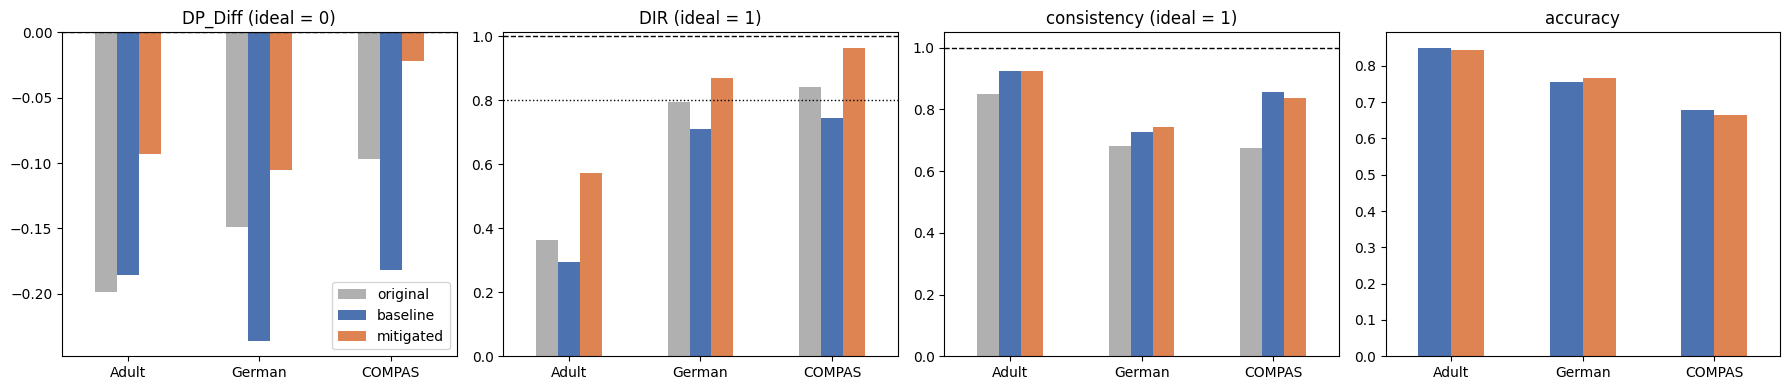

In [40]:
# create the results folder if it doesn't exist yet
os.makedirs("results", exist_ok=True)  
 
# plotted results
colors = {"original": "#b0b0b0", "baseline": "#4c72b0", "mitigated": "#dd8452"}
panels = [("DP_Diff", 0), ("DIR", 1), ("consistency", 1), ("accuracy", None)]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (measure, ideal) in zip(axes, panels):
    comparison[measure].plot.bar(ax=ax, rot=0, color=colors, legend=(measure == "DP_Diff"))
    if ideal is not None:
        ax.axhline(ideal, color="black", linestyle="--", linewidth=1)  # ideal value
    if measure == "DIR":
        ax.axhline(0.8, color="black", linestyle=":", linewidth=1)     # 80% rule
    ax.set_title(measure if ideal is None else f"{measure} (ideal = {ideal})")
    ax.set_xlabel("")

plt.tight_layout()
plt.savefig("results/fairness_comparison.png", dpi=150)  
plt.show()